# Name :- Patel Viraj
## PRN :- 31

# Part 1: Motor Trend Car Road Tests (mtcars)

### Question 1.1: Independent Two-Sample t-Test
* Test difference in mean mpg between 4-cylinder and 6-cylinder cars.
* Perform t-test and display results.
* Conclusion on hypothesis.

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Load mtcars dataset
mtcars = pd.read_csv('/content/mtcars.csv')

# Filter 4-cylinder and 6-cylinder cars
mpg_4 = mtcars[mtcars['cyl'] == 4]['mpg']
mpg_6 = mtcars[mtcars['cyl'] == 6]['mpg']

print("Hypotheses:")
print("H0: There is no difference in the mean mpg between 4-cylinder and 6-cylinder cars (mean_4 = mean_6).")
print("H1: There is a significant difference in the mean mpg between 4-cylinder and 6-cylinder cars (mean_4 != mean_6).\n")

print(f"Sample Mean (4 cylinders): {mpg_4.mean():.3f}")
print(f"Sample Mean (6 cylinders): {mpg_6.mean():.3f}\n")

t_stat, p_val = stats.ttest_ind(mpg_4, mpg_6, equal_var=False)


n1, n2 = len(mpg_4), len(mpg_6)
s1, s2 = mpg_4.var(), mpg_6.var()
df = ((s1/n1 + s2/n2)**2) / ((s1/n1)**2/(n1-1) + (s2/n2)**2/(n2-1))
mean_diff = mpg_4.mean() - mpg_6.mean()
std_err = np.sqrt(s1/n1 + s2/n2)
margin_of_error = stats.t.ppf(0.975, df) * std_err
ci = (mean_diff - margin_of_error, mean_diff + margin_of_error)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")
print(f"95% Confidence Interval for the difference in means: {ci}\n")

print("Conclusion on hypothesis:")
if p_val < 0.05:
    print("Reject the null hypothesis (H0). The difference in mean mpg is statistically significant.")
else:
    print("Fail to reject the null hypothesis (H0). The difference in mean mpg is not statistically significant.")

print("\nInterpretation:")
print(f"On average, 4-cylinder cars obtain {mean_diff:.2f} more miles per gallon compared to 6-cylinder cars.")

Hypotheses:
H0: There is no difference in the mean mpg between 4-cylinder and 6-cylinder cars (mean_4 = mean_6).
H1: There is a significant difference in the mean mpg between 4-cylinder and 6-cylinder cars (mean_4 != mean_6).

Sample Mean (4 cylinders): 26.664
Sample Mean (6 cylinders): 19.743

t-statistic: 4.7191
p-value: 4.0485e-04
95% Confidence Interval for the difference in means: (np.float64(3.751376450669788), np.float64(10.090181990888652))

Conclusion on hypothesis:
Reject the null hypothesis (H0). The difference in mean mpg is statistically significant.

Interpretation:
On average, 4-cylinder cars obtain 6.92 more miles per gallon compared to 6-cylinder cars.


### Question 1.2: One-Way ANOVA Test
* Test if mean horsepower (hp) differs by gear group.
* Perform ANOVA and show summary.
* Interpret results.

In [3]:
print("Hypotheses:")
print("H0: The mean horsepower (hp) is the same across all gear groups.")
print("H1: At least one gear group has a different mean horsepower (hp).\n")


model = ols('hp ~ C(gear)', data=mtcars).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("ANOVA Table Summary:")
print(anova_table)
print("")

p_val_anova = anova_table['PR(>F)'].iloc[0]
print(f"p-value: {p_val_anova:.4f}")

print("\nConclusion on hypothesis:")
if p_val_anova < 0.05:
    print("Reject the null hypothesis (H0). The mean horsepower differs significantly by gear group.")
else:
    print("Fail to reject the null hypothesis (H0). There is no significant difference in mean horsepower by gear group.")

Hypotheses:
H0: The mean horsepower (hp) is the same across all gear groups.
H1: At least one gear group has a different mean horsepower (hp).

ANOVA Table Summary:
                sum_sq    df          F   PR(>F)
C(gear)   64212.941667   2.0  11.422436  0.00022
Residual  81513.933333  29.0        NaN      NaN

p-value: 0.0002

Conclusion on hypothesis:
Reject the null hypothesis (H0). The mean horsepower differs significantly by gear group.


# Part 2: Wine Quality Dataset

### Question 2.1: Correlation, Covariance and Outlier Analysis
* Calculate covariance between alcohol and sulphates.
* Calculate correlation between alcohol and quality.
* Draw scatter plot of alcohol vs quality.
* Detect outliers in alcohol using IQR method.
* Remove outliers and recalculate correlation.

Covariance between alcohol and sulphates: 0.0169
Correlation between alcohol and quality: 0.4762



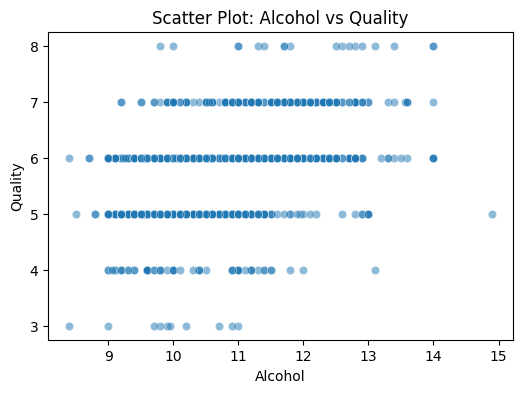

Number of outliers detected in alcohol: 13
Recalculated correlation between alcohol and quality (outliers removed): 0.4710


In [9]:

wine = pd.read_csv('/content/wine_quality_red.csv', sep=';')


cov_val = wine['alcohol'].cov(wine['sulphates'])
print(f"Covariance between alcohol and sulphates: {cov_val:.4f}")


corr_val = wine['alcohol'].corr(wine['quality'])
print(f"Correlation between alcohol and quality: {corr_val:.4f}\n")

plt.figure(figsize=(6, 4))
sns.scatterplot(data=wine, x='alcohol', y='quality', alpha=0.5)
plt.title('Scatter Plot: Alcohol vs Quality')
plt.xlabel('Alcohol')
plt.ylabel('Quality')
plt.show()


Q1 = wine['alcohol'].quantile(0.25)
Q3 = wine['alcohol'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = wine[(wine['alcohol'] < lower_bound) | (wine['alcohol'] > upper_bound)]
print(f"Number of outliers detected in alcohol: {len(outliers)}")


wine_clean = wine[(wine['alcohol'] >= lower_bound) & (wine['alcohol'] <= upper_bound)]
corr_val_clean = wine_clean['alcohol'].corr(wine_clean['quality'])
print(f"Recalculated correlation between alcohol and quality (outliers removed): {corr_val_clean:.4f}")

### Question 2.2: Independent Two-Sample t-Test
* Create two groups:
  * Group A: Wines with quality <= 5
  * Group B: Wines with quality > 5
* Compare the mean alcohol content of the two groups using Independent Two-Sample t-Test.

In [10]:
group_A = wine[wine['quality'] <= 5]['alcohol']
group_B = wine[wine['quality'] > 5]['alcohol']

print("Hypotheses:")
print("H0: The mean alcohol content is identical in both groups (mean_A = mean_B).")
print("H1: The mean alcohol content is different between the two groups (mean_A != mean_B).\n")

print(f"Group A (Quality <= 5) Mean Alcohol: {group_A.mean():.3f}")
print(f"Group B (Quality > 5) Mean Alcohol: {group_B.mean():.3f}\n")

# Perform t-test
t_stat_wine, p_val_wine = stats.ttest_ind(group_A, group_B, equal_var=False)
print(f"t-statistic: {t_stat_wine:.4f}")
print(f"p-value: {p_val_wine:.4e}")

print("\nConclusion on hypothesis:")
if p_val_wine < 0.05:
    print("Reject the null hypothesis (H0). The difference in mean alcohol content between low and high-quality wines is statistically significant.")
else:
    print("Fail to reject the null hypothesis (H0). The difference is not statistically significant.")

Hypotheses:
H0: The mean alcohol content is identical in both groups (mean_A = mean_B).
H1: The mean alcohol content is different between the two groups (mean_A != mean_B).

Group A (Quality <= 5) Mean Alcohol: 9.926
Group B (Quality > 5) Mean Alcohol: 10.855

t-statistic: -19.7822
p-value: 1.1395e-77

Conclusion on hypothesis:
Reject the null hypothesis (H0). The difference in mean alcohol content between low and high-quality wines is statistically significant.


# Part 3: Student Performance Dataset

### Question 3.1: Linear Regression Model
* Split data into 70% training and 30% testing.
* Build linear regression model: `G3 ~ G1 + G2 + studytime`.
* Predict final grades and calculate RMSE.
* Interpret model coefficients.

In [6]:
# Load student dataset
students = pd.read_csv('/content/student-mat.csv', sep=';' if ';' in open('/content/student-mat.csv').readline() else ',')

# Select independent variables and target
X = students[['G1', 'G2', 'studytime']]
y = students['G3']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Build model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predictions
y_pred = lr_model.predict(X_test)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}\n")

# Coefficients
print("Model Coefficients:")
for col, coef in zip(X.columns, lr_model.coef_):
    print(f"{col}: {coef:.4f}")
print(f"Intercept: {lr_model.intercept_:.4f}")

Root Mean Squared Error (RMSE): 2.0833

Model Coefficients:
G1: 0.1740
G2: 0.9875
studytime: -0.0823
Intercept: -1.9076


### Question 3.2: One-Way ANOVA Test
* Categorize students into three study-time groups based on the studytime attribute.
* Compare mean final grades (G3) among the study-time groups using ANOVA.

In [7]:
print("Hypotheses:")
print("H0: Study time has no significant effect on final grades (G3) (equal means).")
print("H1: Study time has a significant effect on final grades (G3) (at least one mean differs).\n")

# Studytime is already ordinal (1, 2, 3, 4). Let's group studytime = 3 and 4 together or categorize into 3 groups:
# e.g., Low (1), Medium (2), High (3 & 4)
def categorize_studytime(st):
    if st == 1:
        return 'Low'
    elif st == 2:
        return 'Medium'
    else:
        return 'High'

students['studytime_group'] = students['studytime'].apply(categorize_studytime)

# Run ANOVA
model_student = ols('G3 ~ C(studytime_group)', data=students).fit()
anova_student = sm.stats.anova_lm(model_student, typ=2)
print(anova_student)

p_val_student_anova = anova_student['PR(>F)'].iloc[0]
print(f"\np-value: {p_val_student_anova:.4f}")
if p_val_student_anova < 0.05:
    print("Conclusion: Reject H0. Study time has a significant effect on final grades (G3).")
else:
    print("Conclusion: Fail to reject H0. Study time does not have a significant effect on final grades (G3).")

Hypotheses:
H0: Study time has no significant effect on final grades (G3) (equal means).
H1: Study time has a significant effect on final grades (G3) (at least one mean differs).

                         sum_sq     df         F    PR(>F)
C(studytime_group)   107.822296    2.0  2.589187  0.076365
Residual            8162.086564  392.0       NaN       NaN

p-value: 0.0764
Conclusion: Fail to reject H0. Study time does not have a significant effect on final grades (G3).


### Question 3.3: Statistical Measures & Outliers of G3
* Calculate mean, median, mode of Final Grade (G3).
* Calculate variance and standard deviation.
* Draw histogram and boxplot.
* Detect outliers using IQR.

Mean: 10.42
Median: 11.00
Mode: 10.00
Variance: 20.99
Standard Deviation: 4.58



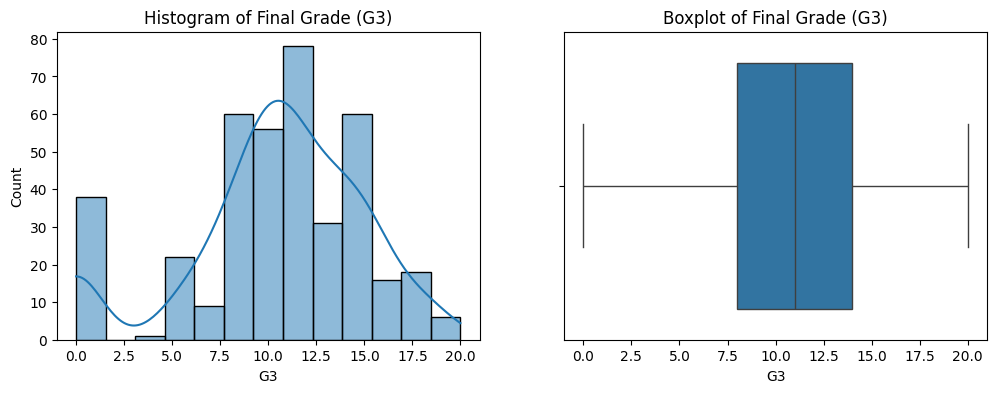

Number of outliers detected in G3: 0


In [8]:
g3_mean = students['G3'].mean()
g3_median = students['G3'].median()
g3_mode = students['G3'].mode().iloc[0]
g3_var = students['G3'].var()
g3_std = students['G3'].std()

print(f"Mean: {g3_mean:.2f}")
print(f"Median: {g3_median:.2f}")
print(f"Mode: {g3_mode:.2f}")
print(f"Variance: {g3_var:.2f}")
print(f"Standard Deviation: {g3_std:.2f}\n")

# Draw Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(students['G3'], kde=True, ax=axes[0])
axes[0].set_title('Histogram of Final Grade (G3)')

sns.boxplot(x=students['G3'], ax=axes[1])
axes[1].set_title('Boxplot of Final Grade (G3)')
plt.show()

# Detect outliers via IQR
Q1_g3 = students['G3'].quantile(0.25)
Q3_g3 = students['G3'].quantile(0.75)
IQR_g3 = Q3_g3 - Q1_g3
lower_bound_g3 = Q1_g3 - 1.5 * IQR_g3
upper_bound_g3 = Q3_g3 + 1.5 * IQR_g3

outliers_g3 = students[(students['G3'] < lower_bound_g3) | (students['G3'] > upper_bound_g3)]
print(f"Number of outliers detected in G3: {len(outliers_g3)}")